<a href="https://colab.research.google.com/github/batu-uchicago/bayes-applications/blob/main/Markov%20Chain%20Monte%20Carlo/mcmc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PyMC: write the model, get the samples

In week 5 we wrote Metropolis-Hastings by hand.
PyMC does the bookkeeping for us: we write the model, one line a node of its Bayes net, and `pm.sample()` draws from the posterior.

Three models, as in the week 6 slides:

1. **A straight line** with Normal noise, next to the least-squares line.
2. **The same line with Rician noise**, the noise of MRI magnitude images, where least squares goes wrong.
3. **Weight from height**: McElreath's geometric people, on Nancy Howell's census of the !Kung San.

## 1. Setup

Run the cell below once. On Colab it installs PyMC if it is missing, and downloads the data file.

In [1]:
# On your laptop, `pip install -r requirements.txt` (see the README) has installed everything.
import os, subprocess, sys, urllib.request

if "google.colab" in sys.modules:
    try:
        import pymc
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymc"], check=True)
    if not os.path.exists("Howell1.csv"):
        urllib.request.urlretrieve("https://raw.githubusercontent.com/batu-uchicago/bayes-applications/main/"
                                   "Markov%20Chain%20Monte%20Carlo/Howell1.csv", "Howell1.csv")
print("Setup complete.")

Setup complete.


In [2]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
from scipy import stats

INK, MAROON, MUTE = "#101014", "#800000", "#6A6A72"
CHAINS = [INK, MAROON, MUTE, "#C99A9A"]   # one colour a chain


def trace_plot(trace, names):
    # for each parameter, each chain's draws as a histogram (left) and as a path (right)
    _, axs = plt.subplots(len(names), 2, figsize=(12, 2.4 * len(names)), squeeze=False)
    for (left, right), name in zip(axs, names):
        for c, chain in enumerate(trace.posterior[name].values):    # chains x draws
            left.hist(chain, bins=40, density=True, histtype="step", color=CHAINS[c % 4])
            right.plot(chain, lw=0.5, color=CHAINS[c % 4], alpha=0.8)
        left.set(title=name, yticks=[])
        right.set(title=f"{name}, chain by chain", xlabel="draw")
    plt.tight_layout()
    plt.show()


def band(draws, prob=0.94):
    # the central prob of the draws at each x; draws has one row a posterior draw
    tail = 100 * (1 - prob) / 2
    return np.percentile(draws, [tail, 100 - tail], axis=0)

## 2. A straight line

Fifty points on the line $y = 1.5 + 2x$, each with Normal noise of standard deviation 1.
We pretend not to know the three numbers.

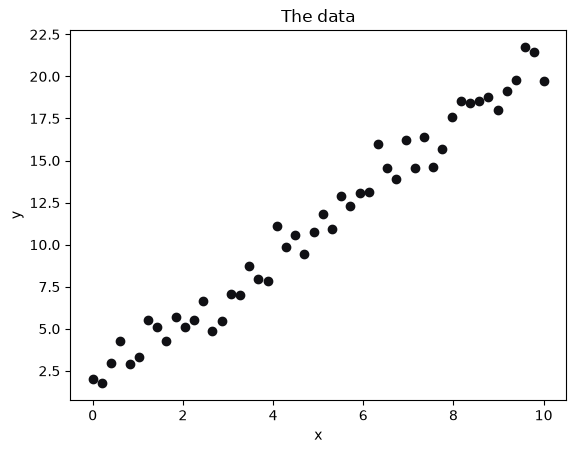

In [3]:
b0_true, b1_true, sigma_true = 1.5, 2.0, 1.0

np.random.seed(42)
x = np.linspace(0, 10, 50)
y = b0_true + b1_true * x + np.random.normal(0, sigma_true, size=x.shape)

plt.scatter(x, y, color=INK)
plt.xlabel("x")
plt.ylabel("y")
plt.title("The data")
plt.show()

The model is the Bayes net of the slides, one line a node:

- $\beta_0 \sim \mathcal{N}(0, 10)$ and $\beta_1 \sim \mathcal{N}(0, 10)$, wide priors on the intercept and the slope,
- $\sigma \sim \text{HalfNormal}(1)$, the noise,
- $\hat y = \beta_0 + \beta_1 x$, and $y \sim \mathcal{N}(\hat y, \sigma)$.

We ask for week 5's sampler, Metropolis, by name.
Left to itself, `pm.sample()` picks NUTS, a Metropolis-Hastings that steers its proposals with the gradient; section 3 uses it.

In [4]:
import warnings

# PyMC's Metropolis bookkeeping overflows a statistic it reports; the draws are unaffected
warnings.filterwarnings("ignore", message="overflow encountered in exp", category=RuntimeWarning)

with pm.Model() as line_model:
    b0 = pm.Normal("b0", mu=0, sigma=10)
    b1 = pm.Normal("b1", mu=0, sigma=10)
    sigma = pm.HalfNormal("sigma", sigma=1)
    y_hat = b0 + b1 * x
    pm.Normal("y", mu=y_hat, sigma=sigma, observed=y)
    trace = pm.sample(1000, tune=1000, step=pm.Metropolis(), random_seed=42)

Multiprocess sampling (4 chains in 4 jobs)


CompoundStep


>Metropolis: [b0]


>Metropolis: [b1]


>Metropolis: [sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 0 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


**Is the chain done?**
Each row of the trace plot is one parameter: its draws on the left, one curve a chain, and the chains' paths on the right.
The chains should agree, and their paths should look like noise around a level, with no trend.
In the summary, `r_hat` should be at most 1.01, and `ess_bulk`, the number of effectively independent draws, should be in the hundreds.

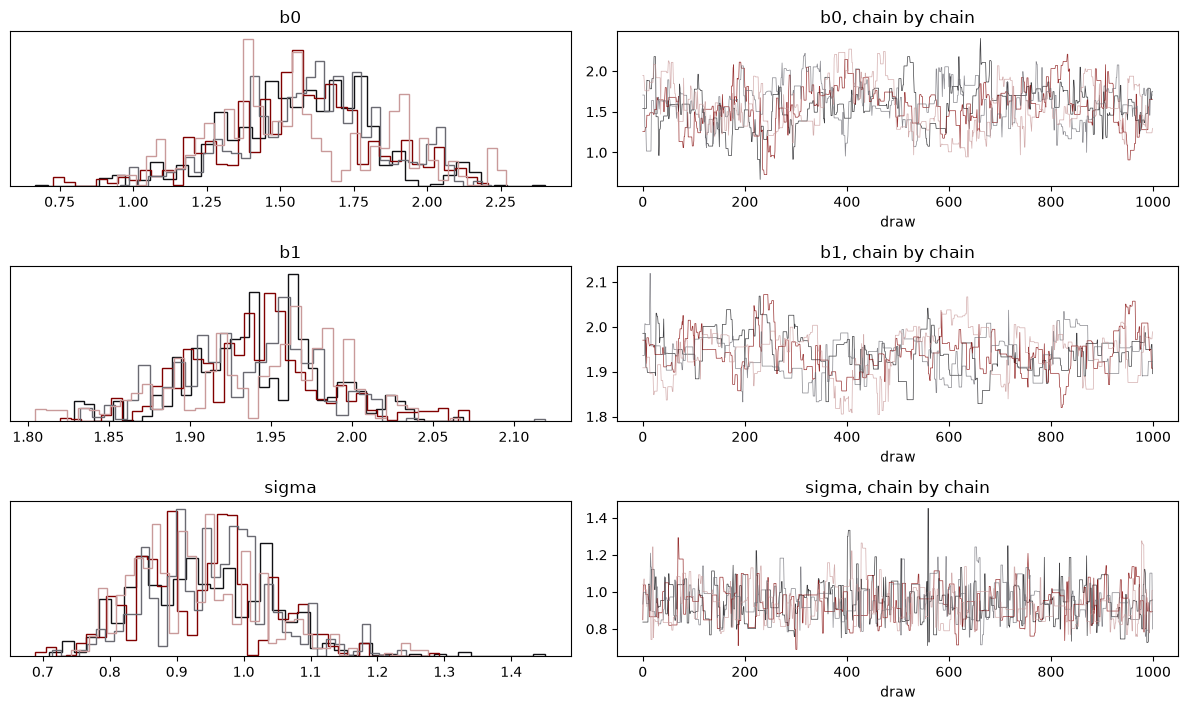

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
b0,1.58,0.26,1.2,2,82,153,1.04,0.029,0.013
b1,1.941,0.045,1.9,2,86,99,1.04,0.0049,0.0024
sigma,0.942,0.098,0.8,1.1,485,582,1.01,0.0044,0.0032


In [5]:
trace_plot(trace, ["b0", "b1", "sigma"])
az.summary(trace, var_names=["b0", "b1", "sigma"])

Here the chain is not done, and PyMC says so above.
On our run `r_hat` is 1.04 for $\beta_0$ and $\beta_1$, and `ess_bulk` is about 80 out of 4,000 draws.
The trouble is that $\beta_0$ and $\beta_1$ are tied together: $x$ runs from 0 to 10, so a steeper line needs a lower intercept to pass through the points.
The posterior is a narrow diagonal ridge, and Metropolis, which moves one parameter at a time, crosses it in tiny steps.
We could run it much longer.
Or we let `pm.sample()` choose the sampler: NUTS follows the gradient along the ridge.

In [6]:
with line_model:
    trace = pm.sample(random_seed=42)

az.summary(trace, var_names=["b0", "b1", "sigma"])

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [b0, b1, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 0 seconds.


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
b0,1.58,0.27,1.2,2,1573,1686,1.00,0.0068,0.0055
b1,1.941,0.046,1.9,2,1546,1678,1.00,0.0012,0.00094
sigma,0.942,0.098,0.8,1.1,2209,2112,1.00,0.0021,0.0019


Same model, same data: now `r_hat` is 1.00 and `ess_bulk` is above 2,000.
The posterior means hardly moved; what changed is that we can trust them.

Every draw of $(\beta_0, \beta_1)$ is a line.
Their mean is the posterior mean line, and the band holds 94% of them at each $x$.

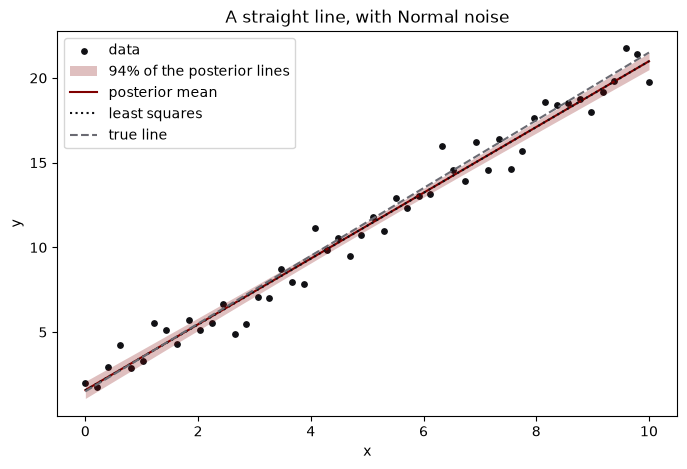

posterior mean: b0 = 1.58, b1 = 1.94
least squares:  b0 = 1.56, b1 = 1.94


In [7]:
b0_draws = trace.posterior["b0"].values.flatten()
b1_draws = trace.posterior["b1"].values.flatten()

x_new = np.linspace(x.min(), x.max(), 100)
lines = b0_draws[:, None] + b1_draws[:, None] * x_new     # one row a posterior draw
low, high = band(lines)

slope, intercept = np.polyfit(x, y, 1)                     # least squares

plt.figure(figsize=(8, 5))
plt.scatter(x, y, color=INK, s=15, label="data")
plt.fill_between(x_new, low, high, color=MAROON, alpha=0.25, lw=0, label="94% of the posterior lines")
plt.plot(x_new, lines.mean(axis=0), color=MAROON, label="posterior mean")
plt.plot(x_new, intercept + slope * x_new, color=INK, linestyle=":", label="least squares")
plt.plot(x_new, b0_true + b1_true * x_new, color=MUTE, linestyle="--", label="true line")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("A straight line, with Normal noise")
plt.show()

print(f"posterior mean: b0 = {b0_draws.mean():.2f}, b1 = {b1_draws.mean():.2f}")
print(f"least squares:  b0 = {intercept:.2f}, b1 = {slope:.2f}")

The posterior mean and the least-squares line nearly coincide, and that is no accident.
Legendre published least squares in 1805: the line with the smallest sum of squared misses.
Gauss showed in 1809 that it is also the most probable line, if the noise is Normal and every line is equally likely beforehand.
Our priors are wide and our noise is Normal, so the posterior peaks where least squares does.
What the posterior adds is the band: how sure we can be of the line.

## 3. The same line, with Rician noise

An MRI scanner measures a complex signal and shows its magnitude.
Normal noise on the real and the imaginary parts becomes Rician noise on the magnitude: it is never negative, and it pushes weak signals up.
Least squares assumes Normal noise, so it fits that push as if it were signal.

The true line is $y = 1.5 + 2x$ again, now for $x$ from 0 to 2, with noise of scale 2.

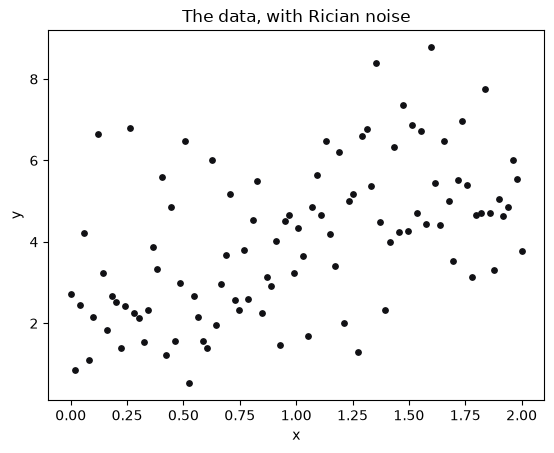

In [8]:
b0_true, b1_true, sigma_true = 1.5, 2.0, 2.0

np.random.seed(42)
x = np.linspace(0, 2, 100)
signal = b0_true + b1_true * x
# Rician noise: scipy's rice(b, scale) has b = signal / scale
y = stats.rice.rvs(b=signal / sigma_true, scale=sigma_true, size=x.shape)

plt.scatter(x, y, color=INK, s=15)
plt.xlabel("x")
plt.ylabel("y")
plt.title("The data, with Rician noise")
plt.show()

In PyMC the likelihood line changes: `pm.Rice` in place of `pm.Normal`.

One more change.
Rician noise needs a signal that is not negative, and a line with $\beta_0, \beta_1 \sim \mathcal{N}(0, 10)$ can dip below zero.
Each time the sampler wanders there it hits a wall, and PyMC reports hundreds of divergences.
An MRI signal is never negative, so we put the priors on the two ends of the line instead: the signal at $x = 0$ and at $x = 2$, both $\text{HalfNormal}(10)$.
The line between two non-negative ends can't go below zero, and $\beta_0$ and $\beta_1$ follow from the ends.

This time `pm.sample()` chooses the sampler, NUTS.

In [9]:
with pm.Model() as rice_model:
    start = pm.HalfNormal("start", sigma=10)    # the signal at x = 0
    end = pm.HalfNormal("end", sigma=10)        # the signal at x = 2
    b0 = pm.Deterministic("b0", start)
    b1 = pm.Deterministic("b1", (end - start) / 2)
    sigma = pm.HalfNormal("sigma", sigma=3)
    y_hat = b0 + b1 * x
    pm.Rice("y", nu=y_hat, sigma=sigma, observed=y)
    trace = pm.sample(random_seed=42)

az.summary(trace, var_names=["b0", "b1", "sigma"])

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [start, end, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 0 seconds.


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
b0,1.33,0.52,0.42,2.1,1432,1242,1.00,0.014,0.0093
b1,2.08,0.37,1.5,2.7,1456,1547,1.00,0.0098,0.0061
sigma,1.832,0.172,1.6,2.1,1466,1653,1.00,0.0044,0.003


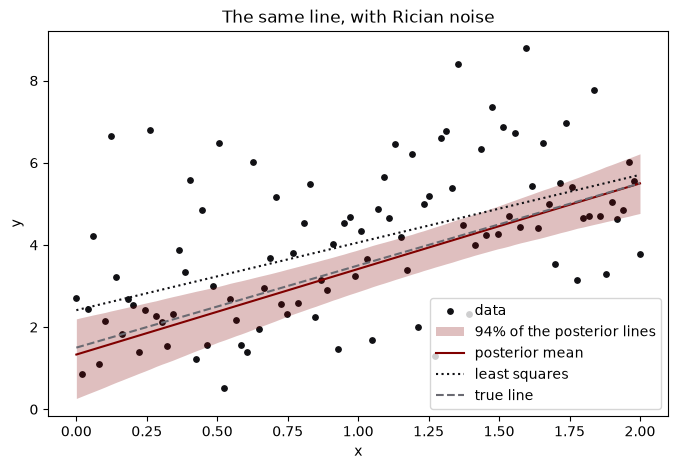

posterior mean: b0 = 1.33, b1 = 2.08
least squares:  b0 = 2.41, b1 = 1.65   (true: 1.5, 2.0)


In [10]:
b0_draws = trace.posterior["b0"].values.flatten()
b1_draws = trace.posterior["b1"].values.flatten()

lines = b0_draws[:, None] + b1_draws[:, None] * x
low, high = band(lines)
slope, intercept = np.polyfit(x, y, 1)

plt.figure(figsize=(8, 5))
plt.scatter(x, y, color=INK, s=15, label="data")
plt.fill_between(x, low, high, color=MAROON, alpha=0.25, lw=0, label="94% of the posterior lines")
plt.plot(x, lines.mean(axis=0), color=MAROON, label="posterior mean")
plt.plot(x, intercept + slope * x, color=INK, linestyle=":", label="least squares")
plt.plot(x, b0_true + b1_true * x, color=MUTE, linestyle="--", label="true line")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("The same line, with Rician noise")
plt.show()

print(f"posterior mean: b0 = {b0_draws.mean():.2f}, b1 = {b1_draws.mean():.2f}")
print(f"least squares:  b0 = {intercept:.2f}, b1 = {slope:.2f}   (true: 1.5, 2.0)")

Least squares says $\beta_0 = 2.41$ and $\beta_1 = 1.65$.
Near $x = 0$ the signal is weak and the noise pushes the measurements up the most, so least squares lifts the start of the line and flattens its slope.
The posterior knows the noise is Rician.
It lands near the true line, $\beta_0 \approx 1.33$ and $\beta_1 \approx 2.08$, and its band covers $y = 1.5 + 2x$.

## 4. Weight from height

Nancy Howell's census of the !Kung San of the Kalahari: the height (cm), weight (kg), age and sex of 544 people, children included.
We divide each height and each weight by its mean, so that both are near 1.

In [11]:
df = pd.read_csv("Howell1.csv", sep=";")
df["height_scaled"] = df.height / df.height.mean()
df["weight_scaled"] = df.weight / df.weight.mean()
df.head()

,height,weight,age,male,height_scaled,weight_scaled
0,151.765,47.825606,63.0,1,1.097650,1.343015
1,139.700,36.485807,63.0,0,1.010389,1.024577
2,136.525,31.864838,65.0,0,0.987425,0.894813
3,156.845,53.041914,41.0,1,1.134391,1.489497
4,145.415,41.276872,51.0,0,1.051723,1.159117


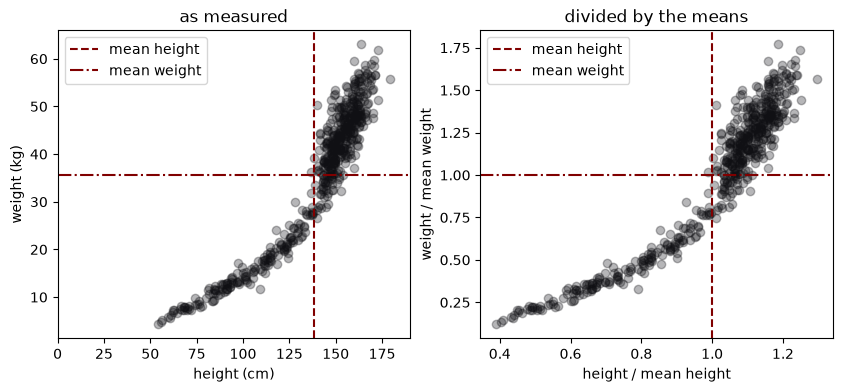

In [12]:
_, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].scatter(df.height, df.weight, color=INK, alpha=0.3)
axs[0].axvline(df.height.mean(), color=MAROON, linestyle="--", label="mean height")
axs[0].axhline(df.weight.mean(), color=MAROON, linestyle="-.", label="mean weight")
axs[0].set(xlim=(0, 190), xlabel="height (cm)", ylabel="weight (kg)", title="as measured")
axs[0].legend()

axs[1].scatter(df.height_scaled, df.weight_scaled, color=INK, alpha=0.3)
axs[1].axvline(1, color=MAROON, linestyle="--", label="mean height")
axs[1].axhline(1, color=MAROON, linestyle="-.", label="mean weight")
axs[1].set(xlabel="height / mean height", ylabel="weight / mean weight", title="divided by the means")
axs[1].legend()
plt.show()

Picture a person as a cylinder (McElreath, *Statistical Rethinking*, 2nd ed., section 16.1).
Its radius $r$ is some share $p$ of its height $H$:

$$r = pH$$

Its weight is its volume times its density $k$:

$$W \propto \pi r^2 H k = \pi k p^2 H^3$$

So weight grows as the cube of height, and the model has two parameters, $p$ and $k$, plus the noise $\sigma$.

The priors:

- $p \sim \text{Beta}(25, 50)$: a radius about a third of the height, since $25 / (25 + 50) = 1/3$.
- $k \sim \text{Exponential}(0.5)$: a positive density, 2 on average.
- $\sigma \sim \text{Exponential}(1)$, for the noise.

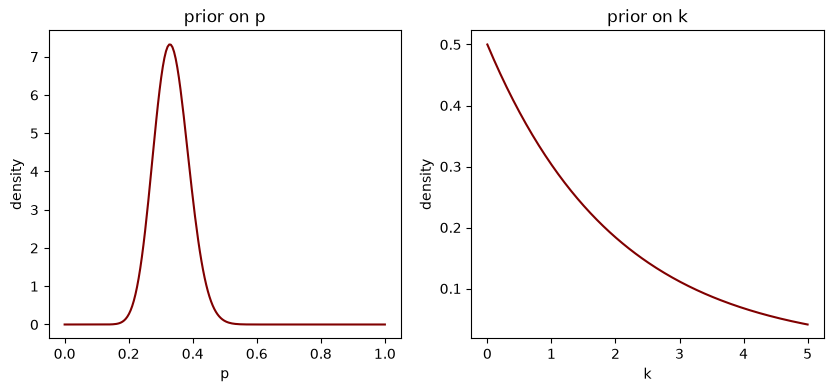

In [13]:
p_prior = stats.beta(a=25, b=50)
k_prior = stats.expon(scale=1 / 0.5)    # scipy's scale is 1 / rate
ps = np.linspace(0, 1, 200)
ks = np.linspace(0, 5, 200)

_, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].plot(ps, p_prior.pdf(ps), color=MAROON)
axs[0].set(xlabel="p", ylabel="density", title="prior on p")
axs[1].plot(ks, k_prior.pdf(ks), color=MAROON)
axs[1].set(xlabel="k", ylabel="density", title="prior on k")
plt.show()

What do these priors say before we see any data?
We draw 100 sets of $(p, k, \sigma)$ from them and plot the expected weight that each set gives at every height.

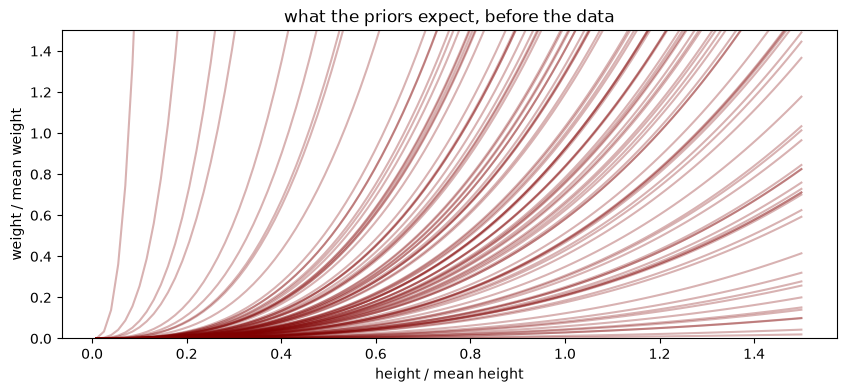

In [14]:
np.random.seed(42)
n = 100
p_draws = p_prior.rvs(size=n)
k_draws = k_prior.rvs(size=n)
sigma_draws = stats.expon(scale=1).rvs(size=n)

heights = np.linspace(0.01, 1.5, 100)[:, None]
log_mu = np.log(np.pi * k_draws * p_draws**2 * heights**3)
expected_weight = np.exp(log_mu + sigma_draws**2 / 2)    # the mean of a LogNormal

plt.figure(figsize=(10, 4))
plt.plot(heights, expected_weight, color=MAROON, alpha=0.3)
plt.ylim(0, 1.5)
plt.xlabel("height / mean height")
plt.ylabel("weight / mean weight")
plt.title("what the priors expect, before the data")
plt.show()

The model, as on the slides:

$$W \sim \text{LogNormal}\big(\log(\pi k p^2 H^3),\ \sigma\big)$$

The heights go in through `pm.Data`, so that we can swap in new heights later and predict their weights.

In [15]:
with pm.Model() as people_model:
    H = pm.Data("H", df.height_scaled, dims="obs_id")
    p = pm.Beta("p", alpha=25, beta=50)
    k = pm.Exponential("k", lam=0.5)
    sigma = pm.Exponential("sigma", lam=1)
    mu = pm.math.log(np.pi * k * p**2 * H**3)
    pm.LogNormal("W", mu=mu, sigma=sigma, observed=df.weight_scaled, dims="obs_id")
    people_trace = pm.sample(random_seed=42)

print(people_model.str_repr())

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [p, k, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


    H = Data(<shared>)
    p ~ Beta(25, 50)
    k ~ Exponential(<constant>)
sigma ~ Exponential(<constant>)
    W ~ LogNormal(f(H, p, k), sigma)


In [16]:
az.summary(people_trace, var_names=["p", "k", "sigma"])

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
p,0.34,0.051,0.26,0.42,1348,1451,1.00,0.0014,0.00096
k,2.79,0.91,1.7,4.4,1342,1467,1.00,0.026,0.027
sigma,0.207,0.0063,0.2,0.22,1670,1838,1.00,0.00016,0.00014


On their own, $p$ and $k$ are loosely known: $p$ is about $0.34 \pm 0.05$ and $k$ about $2.8 \pm 0.9$.
But the data pin down the product $k p^2$, about $0.302 \pm 0.003$: a person of mean height has a median weight of $\pi k p^2 \approx 0.95$ mean weights.
A thin person can be dense, or a wide one light, and heights and weights cannot tell the two apart.
So the draws lie along a curve, $k \approx 0.30 / p^2$, and the priors decide where on it we sit.

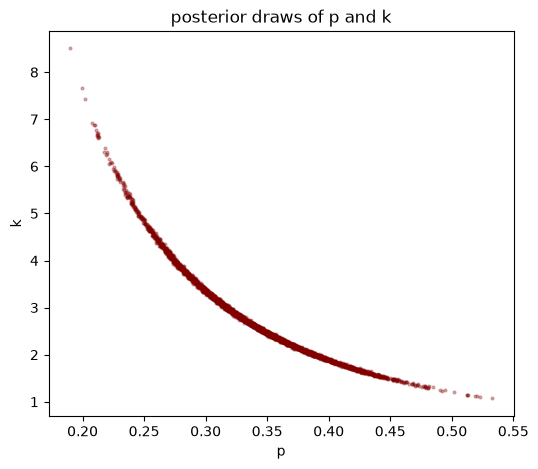

k p^2: mean 0.3016, sd 0.0027


In [17]:
p_post = people_trace.posterior["p"].values.flatten()
k_post = people_trace.posterior["k"].values.flatten()

plt.figure(figsize=(6, 5))
plt.scatter(p_post, k_post, color=MAROON, s=4, alpha=0.3)
plt.xlabel("p")
plt.ylabel("k")
plt.title("posterior draws of p and k")
plt.show()

print(f"k p^2: mean {np.mean(k_post * p_post**2):.4f}, sd {np.std(k_post * p_post**2):.4f}")

Last, the posterior predictive: for new heights from 0 to 1.5 times the mean, the weights the model predicts, with their uncertainty.

Sampling: [W]


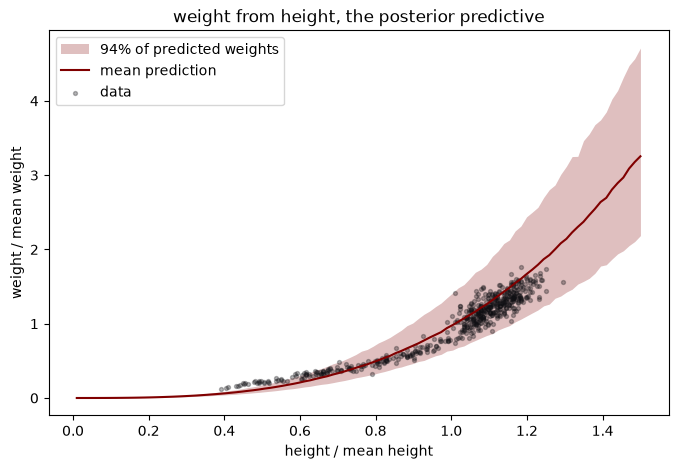

In [18]:
new_heights = np.linspace(0.01, 1.5, 100)
with people_model:
    pm.set_data({"H": new_heights})
    ppd = pm.sample_posterior_predictive(people_trace, predictions=True, random_seed=42)

W_pred = ppd.predictions["W"].values.reshape(-1, len(new_heights))    # one row a posterior draw
low, high = band(W_pred)
plt.figure(figsize=(8, 5))
plt.fill_between(new_heights, low, high, color=MAROON, alpha=0.25, lw=0, label="94% of predicted weights")
plt.plot(new_heights, W_pred.mean(axis=0), color=MAROON, label="mean prediction")
plt.scatter(df.height_scaled, df.weight_scaled, color=INK, s=8, alpha=0.3, label="data")
plt.xlabel("height / mean height")
plt.ylabel("weight / mean weight")
plt.legend()
plt.title("weight from height, the posterior predictive")
plt.show()